# NB10 — Pico Sweep: Amplitudengang H(f) mit CH3 roh vs. CH4 verstärkt

## Versuchsaufbau
- **CH1**: Pico GP14 Trigger-Marker (DC, 1x, 1V/div) → Trigger-Quelle, nicht gelesen
- **CH3**: Piezo **ohne** Verstärker (AC, 1x Tastkopf, `PROB 1`, `SCAL 0.001` = 1 mV/div)
- **CH4**: Piezo **mit** Verstärker (AC, 10x Tastkopf, `PROB 10`, `SCAL 0.5`)
- **Pico GP15**: Sinus-Sweep 5–100 kHz, 30 s Sweep → 1,5 s/Band, 20 Bänder

**Ziel**: Klären ob der Verstärker bei hohen Frequenzen (> 30 kHz) die Bandbreite begrenzt.

---

In [1]:
%matplotlib inline
import sys, time, json
from pathlib import Path
from datetime import datetime
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, '..')
sys.path.insert(0, '../instrument_control')
from scope.config import load_config
from scope.instrument import InstrumentConnection, parse_preamble
from plant_ae.watering import CONFIG_PATH

BANDS_HZ  = list(range(5_000, 101_000, 5_000))
N_BANDS   = 20
N_CAP     = 60
SKIP_S    = 0.10
TRIG_W    = 3.5
TIM_SCAL  = 0.0001
FS_EXPECT = 900_000
CH3_SCAL_INIT = 0.001   # 1 mV/div, Probe 1x physisch + PROB 1

config = load_config(CONFIG_PATH)
print('Config geladen.')

Config geladen.


In [2]:
def configure_scope(conn, ch3_scal=CH3_SCAL_INIT):
    conn.write(':STOP')
    # CH1: Trigger (GP14), DC, nicht gelesen
    conn.write(':CHAN1:DISP ON');  conn.write(':CHAN1:COUP DC')
    conn.write(':CHAN1:SCAL 1.0'); conn.write(':CHAN1:PROB 1'); conn.write(':CHAN1:OFFS 0')
    conn.write(':CHAN2:DISP OFF')
    # CH3: Piezo roh, 1x Probe
    conn.write(':CHAN3:DISP ON');  conn.write(':CHAN3:COUP AC')
    conn.write(f':CHAN3:SCAL {ch3_scal}'); conn.write(':CHAN3:PROB 1'); conn.write(':CHAN3:OFFS 0')
    # CH4: Piezo + Verstärker, 10x Probe
    conn.write(':CHAN4:DISP ON');  conn.write(':CHAN4:COUP AC')
    conn.write(':CHAN4:SCAL 0.5'); conn.write(':CHAN4:PROB 10'); conn.write(':CHAN4:OFFS 0')
    conn.write(f':TIM:SCAL {TIM_SCAL}'); conn.write(':TIM:OFFS 0')
    conn.write(':ACQ:TYPE NORM'); conn.write(':ACQ:MDEP AUTO')
    conn.write(':TRIG:MODE EDGE'); conn.write(':TRIG:EDGE:SOUR CHAN1')
    conn.write(':TRIG:EDGE:SLOP POS'); conn.write(':TRIG:EDGE:LEV 0.5')
    conn.write(':TRIG:SWE NORM')

print('configure_scope definiert.')

configure_scope definiert.


## Messung ausführen
Pico muss laufen (Sweep aktiv). Zelle ausführen startet die Aufnahme von 60 Frames (~2 vollständige Sweeps).

In [3]:
RUN_TS = datetime.now().strftime('%Y%m%d_%H%M%S')
OUT = Path('..') / 'data' / 'pico_sweep_amplitude' / RUN_TS
OUT.mkdir(parents=True, exist_ok=True)
print(f'Output: {OUT}')

records = []
ch3_scal_cur = CH3_SCAL_INIT

with InstrumentConnection(config) as conn:
    configure_scope(conn); time.sleep(0.3)
    print(f'Scope konfiguriert. CH3=1mV/div Prob1, CH4=0.5V/div Prob10. Starte {N_CAP} Captures ...')

    band_start_idx = None; t_prev = None
    capture_n = 0; frame_abs = 0; recfg_count = 0

    while capture_n < N_CAP:
        conn.write(f':TIM:SCAL {TIM_SCAL}')
        conn.write(':SING')
        time.sleep(SKIP_S)
        t0 = time.monotonic()
        triggered = False
        while time.monotonic()-t0 < TRIG_W:
            if conn.query(':TRIG:STAT?').strip().upper() == 'STOP':
                triggered = True; break
            time.sleep(0.008)
        t_trig = time.monotonic()

        if not triggered:
            print(f'  [C{capture_n+1:3d}] kein Trigger → rekonfiguriere')
            configure_scope(conn, ch3_scal_cur); recfg_count += 1
            capture_n += 1; continue

        if t_prev is not None:
            dt = t_trig - t_prev
            missed = max(0, round(dt/1.5) - 1)
            if missed:
                frame_abs += missed
                print(f'  [---] {missed} Band(s) übersprungen Δt={dt:.2f}s')
        t_prev = t_trig
        time.sleep(0.03)

        ch_data = {}; ok = True
        for ch in (3, 4):
            try:
                conn.write(f':WAV:SOUR CHAN{ch}')
                conn.write(':WAV:MODE NORM'); conn.write(':WAV:FORM BYTE')
                pre = parse_preamble(conn.query(':WAV:PRE?'))
                raw = conn.query_binary_values(':WAV:DATA?', datatype='B', is_big_endian=False)
            except Exception as e:
                print(f'  VISA-Fehler CH{ch}: {e}'); ok = False; break
            if len(raw) < 50 or pre.xincrement == 0:
                ok = False; break
            fs = 1.0/pre.xincrement
            if fs < FS_EXPECT:
                print(f'  CH{ch}: fs={fs/1e3:.0f}kSa/s → rekonfiguriere')
                configure_scope(conn, ch3_scal_cur); recfg_count += 1; ok = False; break
            v   = (np.array(raw, dtype=np.float32)-pre.yorigin-pre.yreference)*pre.yincrement
            N   = len(v); win = np.hanning(N)
            fft_c = np.fft.rfft(v*win)
            fft_m = 2*np.abs(fft_c)/win.sum()
            freq  = np.fft.rfftfreq(N, 1/fs)
            ch_data[ch] = dict(v=v, fs=fs, fft=fft_m, fft_c=fft_c, freq=freq, N=N)

        if not ok:
            capture_n += 1; frame_abs += 1; continue

        d3 = ch_data[3]; d4 = ch_data[4]

        # Auto-Scale CH3
        v3_peak = np.max(np.abs(d3['v']))
        disp_full = ch3_scal_cur * 4  # Prob 1x, 4 Div
        if v3_peak > disp_full * 0.85:
            new_scal = min(ch3_scal_cur * 2, 0.05)
            print(f'  CH3 clippt ({v3_peak*1000:.2f}mV) → SCAL {new_scal*1000:.2f}mV/div')
            ch3_scal_cur = new_scal; conn.write(f':CHAN3:SCAL {ch3_scal_cur}')
        elif v3_peak < disp_full * 0.03 and ch3_scal_cur > 0.0005:
            new_scal = max(ch3_scal_cur / 2, 0.0005)
            print(f'  CH3 klein ({v3_peak*1000:.3f}mV) → SCAL {new_scal*1000:.2f}mV/div')
            ch3_scal_cur = new_scal; conn.write(f':CHAN3:SCAL {ch3_scal_cur}')

        # Band-Sync via CH4
        if band_start_idx is None:
            region = (d4['freq'] > 12_000) & (d4['freq'] < 105_000)
            if region.any():
                base = np.median(d4['fft'][region])
                bs, bsnr = None, 0.0
                for b in BANDS_HZ:
                    if b < 12_000: continue
                    idx = np.argmin(np.abs(d4['freq']-b))
                    amp = d4['fft'][max(0,idx-1):idx+2].max()
                    snr = amp/(base+1e-12)
                    if snr > bsnr: bsnr = snr; bs = b
                if bs and bsnr > 4.0:
                    band_start_idx = (BANDS_HZ.index(bs) - frame_abs) % N_BANDS
                    print(f'  Band-Sync: C{capture_n+1}/f{frame_abs} = {bs/1000:.0f}kHz (SNR={bsnr:.1f})')

        cyc_idx = (frame_abs + (band_start_idx or 0)) % N_BANDS
        band_hz = BANDS_HZ[cyc_idx]

        def amp_at(d, f0):
            idx = np.argmin(np.abs(d['freq']-f0))
            return float(d['fft'][idx])

        def tau_us(da, db, f0):
            idx = np.argmin(np.abs(da['freq']-f0))
            dphi = float(np.angle(da['fft_c'][idx]) - np.angle(db['fft_c'][idx]))
            dphi = (dphi+np.pi)%(2*np.pi)-np.pi
            return -dphi/(2*np.pi*f0)*1e6

        a3 = amp_at(d3, band_hz)
        a4 = amp_at(d4, band_hz)
        tau_34 = tau_us(d3, d4, band_hz)

        rec = {
            'capture': capture_n+1, 'frame_abs': frame_abs,
            'ts': datetime.now().isoformat(),
            'band_hz': int(band_hz),
            'amp_ch3_raw': float(a3), 'amp_ch4_amp': float(a4),
            'ch3_scal': ch3_scal_cur,
            'tau_34_us': round(tau_34, 4),
            'fs': round(d4['fs'], 1), 'n_pts': d4['N'],
        }
        records.append(rec)
        with open(OUT/'records.jsonl','a') as f:
            f.write(json.dumps(rec)+'\n')

        ratio_db = 20*np.log10(a4/a3) if a3 > 1e-9 else float('nan')
        print(f'  [C{capture_n+1:3d}] {band_hz/1000:5.1f}kHz  '
              f'CH3_roh={a3*1000:7.4f}mV  CH4_amp={a4*1000:7.3f}mV  '
              f'Ratio={ratio_db:+.1f}dB  τ={tau_34:+.2f}µs')
        capture_n += 1; frame_abs += 1

print(f'\nFertig: {len(records)} Frames, {recfg_count} Rekonfig → {OUT}')

Output: ../data/pico_sweep_amplitude/20260629_222623


Scope konfiguriert. CH3=1mV/div Prob1, CH4=0.5V/div Prob10. Starte 60 Captures ...


  CH3 clippt (5.12mV) → SCAL 2.00mV/div
  Band-Sync: C1/f0 = 30kHz (SNR=33.3)
  [C  1]  30.0kHz  CH3_roh= 0.1660mV  CH4_amp= 71.370mV  Ratio=+52.7dB  τ=+11.11µs


  CH3 clippt (10.24mV) → SCAL 4.00mV/div
  [C  2]  35.0kHz  CH3_roh= 0.2111mV  CH4_amp= 12.094mV  Ratio=+35.2dB  τ=-7.92µs


  CH3 clippt (20.48mV) → SCAL 8.00mV/div
  [C  3]  40.0kHz  CH3_roh= 0.1786mV  CH4_amp=  1.908mV  Ratio=+20.6dB  τ=+2.25µs


...

  [C 56]  75.0kHz  CH3_roh= 0.1213mV  CH4_amp=  4.767mV  Ratio=+31.9dB  τ=+1.38µs


  [C 57]  80.0kHz  CH3_roh= 0.0892mV  CH4_amp=  0.789mV  Ratio=+18.9dB  τ=+2.97µs


  [C 58]  85.0kHz  CH3_roh= 0.1728mV  CH4_amp=  1.162mV  Ratio=+16.6dB  τ=-2.49µs


  [C 59]  90.0kHz  CH3_roh= 0.2046mV  CH4_amp=  1.091mV  Ratio=+14.5dB  τ=+4.42µs


  [C 60]  95.0kHz  CH3_roh= 0.0339mV  CH4_amp=  1.713mV  Ratio=+34.1dB  τ=+4.73µs

Fertig: 54 Frames, 1 Rekonfig → ../data/pico_sweep_amplitude/20260629_222623


## Auswertung & Plot

Band[kHz]  CH3_roh[mV]  CH4_amp[mV]  Ratio[dB]
    5.0      0.1121      13.755    +41.8
   10.0      0.1058      45.911    +52.7
   15.0      0.1410      10.870    +37.7
   20.0      0.1248      23.298    +45.4
   25.0      0.2072      13.995    +36.6
   30.0      0.1730      82.604    +53.6
   35.0      0.1607      10.801    +36.5
   40.0      0.1490       2.009    +22.6
   45.0      0.1869       4.167    +27.0
   55.0      0.1769       7.235    +32.2
   60.0      0.1869       1.175    +16.0
   65.0      0.2890       6.925    +27.6
   70.0      0.2268       1.715    +17.6
   75.0      0.1907       3.470    +25.2
   80.0      0.1750       0.726    +12.4
   85.0      0.1652       1.071    +16.2
   90.0      0.1694       2.090    +21.8
   95.0      0.0872       1.069    +21.8
  100.0      0.3136       1.597    +14.1


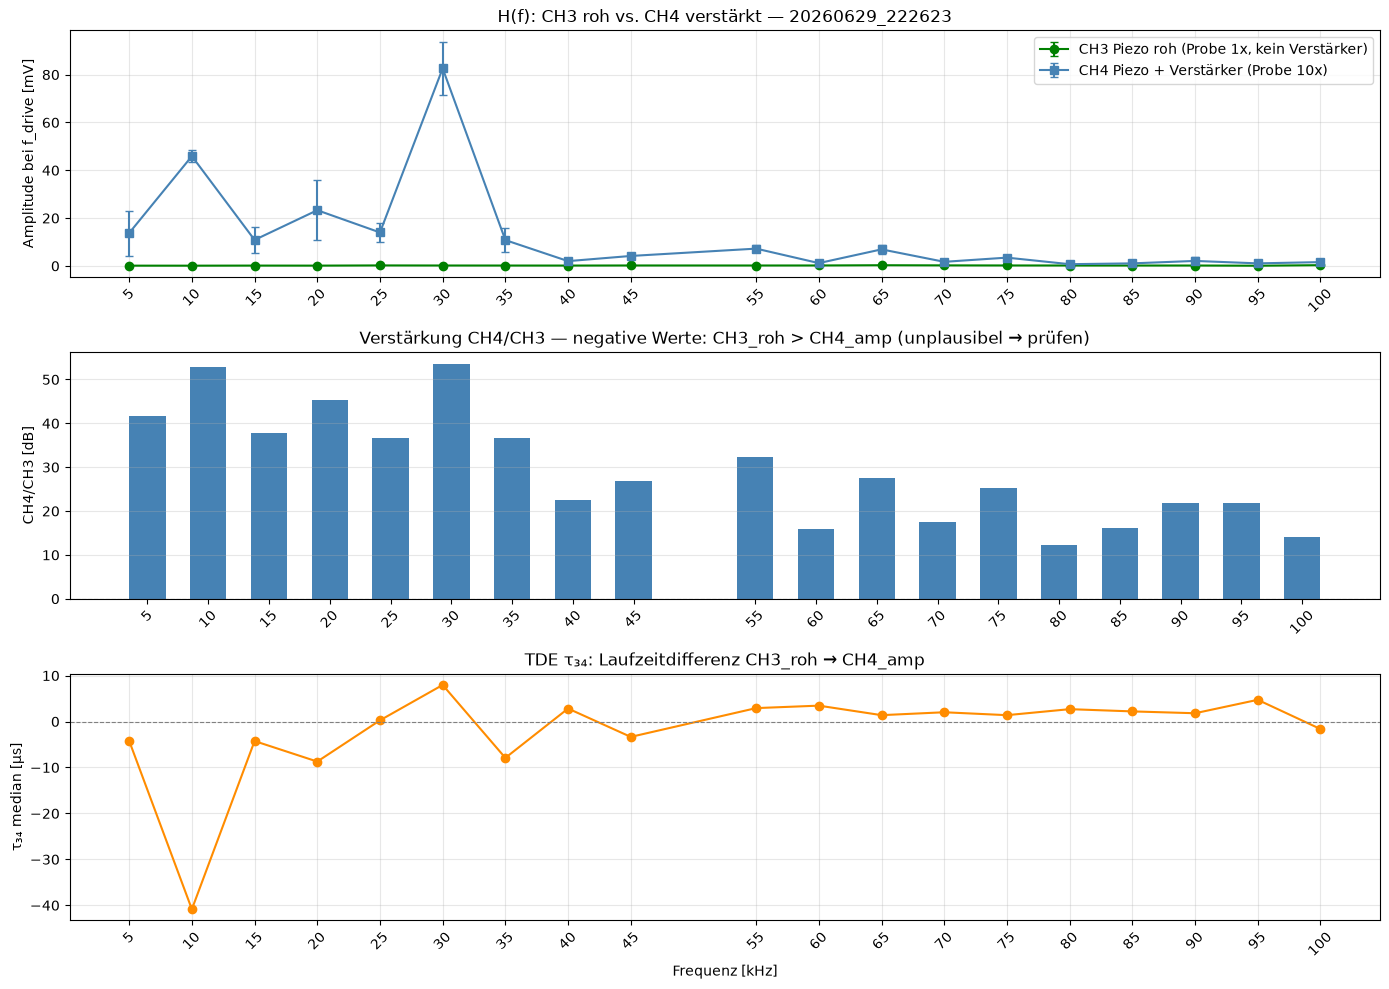

Plot: ../data/pico_sweep_amplitude/20260629_222623/amplitude_response.png


In [4]:
by3 = defaultdict(list); by4 = defaultdict(list); byτ = defaultdict(list)
for r in records:
    by3[r['band_hz']].append(r['amp_ch3_raw'])
    by4[r['band_hz']].append(r['amp_ch4_amp'])
    byτ[r['band_hz']].append(r['tau_34_us'])

bands = sorted(b for b in by4 if by3[b])
bx = [b/1000 for b in bands]
m3 = [np.mean(by3[b])*1000 for b in bands]
m4 = [np.mean(by4[b])*1000 for b in bands]
s3 = [np.std(by3[b])*1000  for b in bands]
s4 = [np.std(by4[b])*1000  for b in bands]
ratio_db = [20*np.log10(m4[i]/m3[i]) if m3[i]>1e-9 else float('nan') for i in range(len(bands))]

print('Band[kHz]  CH3_roh[mV]  CH4_amp[mV]  Ratio[dB]')
for i,b in enumerate(bands):
    print(f'  {b/1000:5.1f}    {m3[i]:8.4f}    {m4[i]:8.3f}    {ratio_db[i]:+.1f}')

fig, axes = plt.subplots(3, 1, figsize=(14, 10))

axes[0].errorbar(bx, m3, yerr=s3, fmt='o-', color='green', capsize=3, label='CH3 Piezo roh (Probe 1x, kein Verstärker)')
axes[0].errorbar(bx, m4, yerr=s4, fmt='s-', color='steelblue', capsize=3, label='CH4 Piezo + Verstärker (Probe 10x)')
axes[0].set_ylabel('Amplitude bei f_drive [mV]')
axes[0].set_title(f'H(f): CH3 roh vs. CH4 verstärkt — {RUN_TS}')
axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[0].set_xticks(bx); axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(bx, [r if not np.isnan(r) else 0 for r in ratio_db],
            color=['steelblue' if not np.isnan(r) and r >= 0 else 'red' for r in ratio_db], width=3)
axes[1].axhline(0, ls='--', color='gray', lw=0.8)
axes[1].set_ylabel('CH4/CH3 [dB]')
axes[1].set_title('Verstärkung CH4/CH3 — negative Werte: CH3_roh > CH4_amp (unplausibel → prüfen)')
axes[1].grid(True, alpha=0.3, axis='y')
axes[1].set_xticks(bx); axes[1].tick_params(axis='x', rotation=45)

axes[2].plot(bx, [np.median(byτ[b]) for b in bands], 'o-', color='darkorange')
axes[2].axhline(0, ls='--', color='gray', lw=0.8)
axes[2].set_xlabel('Frequenz [kHz]'); axes[2].set_ylabel('τ₃₄ median [µs]')
axes[2].set_title('TDE τ₃₄: Laufzeitdifferenz CH3_roh → CH4_amp')
axes[2].grid(True, alpha=0.3)
axes[2].set_xticks(bx); axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(OUT/'amplitude_response.png', dpi=150)
plt.show()
print(f'Plot: {OUT}/amplitude_response.png')